<a href="https://colab.research.google.com/github/KTada777/Bayesian_SolarCell_1D_L_dep/blob/main/260725_pymc5%2Bnutpie_PVparameter_OPV_0_001sun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!cat /proc/cpuinfo | awk '/processor/,/cpu MHz/'

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998
processor	: 1
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998


In [ ]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
!pip install nutpie

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.9/243.9 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.8/183.8 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 85.9 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 0.22.0
    Uninstalling arviz-0.22.0:
      Successfully uninstalled arviz-0.22.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pymc 5.28.5 requires arviz<1.0,>=0.13.0, but yo

In [ ]:
!pip install pymc
import pymc as pm
print(pm.__version__)
import arviz as az

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 15.6 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 1.2.0
    Uninstalling arviz-1.2.0:
      Successfully uninstalled arviz-1.2.0
5.28.5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
import pytensor
pytensor.config.optdb__max_use_ratio = 40.0

In [ ]:
def pm_I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026    #Vt(RT)=26 mV
    x = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt

    return (V - nVt * (pm_Roberts_g(x) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def pm_Roberts_g(x):
    e_1 = np.exp(-1)
    e1 = np.exp(1)
    g = pm.math.switch((x <= -(e_1)), x, pm.math.switch((x >= e1), np.log(x), -e1 + (1 + e1) / (2 * e1) * (x + e1)))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
#
# J-V of PTB7-Th:C70 OPV @0.001 sun.
#

X = np.array([
    0.7, 0.69, 0.679999, 0.67, 0.66, 0.649999, 0.639999,
    0.63, 0.62, 0.609999, 0.6, 0.59, 0.579999, 0.569999,
    0.559999, 0.549999, 0.54, 0.53, 0.519999, 0.509999, 0.499999,
    0.49, 0.479999, 0.469999, 0.46, 0.45, 0.44, 0.43,
    0.42, 0.41, 0.4, 0.39, 0.38, 0.37, 0.359999,
    0.35, 0.34, 0.329999, 0.319999, 0.309999, 0.3, 0.289999,
    0.28, 0.269999, 0.26, 0.25, 0.239999, 0.229999, 0.22,
    0.21, 0.199999, 0.19, 0.179999, 0.17, 0.159999, 0.149999,
    0.14, 0.13, 0.12, 0.11, 0.099999, 0.089999, 0.08,
    0.069999, 0.06, 0.049999, 0.04, 0.029999, 0.019999, 0.009999,
    0.0, 0.0, -0.01, -0.020001, -0.03, -0.040001, -0.05,
    -0.06, -0.070001, -0.08, -0.09, -0.1, -0.11, -0.12,
    -0.13, -0.140001, -0.15, -0.16, -0.17, -0.180001, -0.19,
    -0.200001
])

Y = np.array([
    0.0010964556, 0.00087484889, 0.00068966333, 0.00053762444, 0.00041455667, 0.00031622333,
    0.00023859889, 0.00017788, 0.00013071333, 9.4286667e-05, 6.6263333e-05, 4.4766667e-05,
    2.8293333e-05, 1.5678889e-05, 6.0044444e-06, -1.44e-06, -7.1066667e-06, -1.1511111e-05,
    -1.4902222e-05, -1.7554444e-05, -1.9622222e-05, -2.1224444e-05, -2.2503333e-05, -2.3505556e-05,
    -2.4308889e-05, -2.4955556e-05, -2.549e-05, -2.5918889e-05, -2.6306667e-05, -2.6621111e-05,
    -2.6896667e-05, -2.7114444e-05, -2.7322222e-05, -2.7498889e-05, -2.766e-05, -2.7814444e-05,
    -2.7952222e-05, -2.8101111e-05, -2.8202222e-05, -2.8318889e-05, -2.8443333e-05, -2.8531111e-05,
    -2.8642222e-05, -2.8717778e-05, -2.8823333e-05, -2.8918889e-05, -2.9005556e-05, -2.9091111e-05,
    -2.915e-05, -2.9246667e-05, -2.9323333e-05, -2.9395556e-05, -2.9467778e-05, -2.9527778e-05,
    -2.9597778e-05, -2.9663333e-05, -2.9738889e-05, -2.9788889e-05, -2.985e-05, -2.9906667e-05,
    -2.995e-05, -3.0036667e-05, -3.0087778e-05, -3.014e-05, -3.0218889e-05, -3.0266667e-05,
    -3.0331111e-05, -3.037e-05, -3.0426667e-05, -3.0486667e-05, -3.0525556e-05, -3.0536667e-05,
    -3.0561111e-05, -3.063e-05, -3.0654444e-05, -3.071e-05, -3.0733333e-05, -3.0791111e-05,
    -3.0825556e-05, -3.0874444e-05, -3.0927778e-05, -3.096e-05, -3.0996667e-05, -3.1025556e-05,
    -3.109e-05, -3.1118889e-05, -3.1164444e-05, -3.1197778e-05, -3.1206667e-05, -3.126e-05,
    -3.129e-05, -3.1332222e-05
])

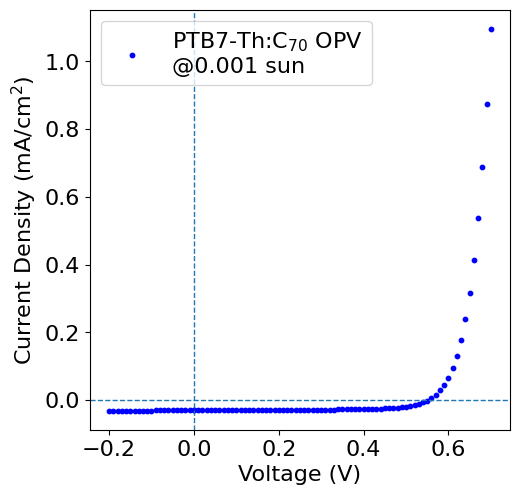

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV\n@0.001 sun'
           )
#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
plt.legend()

In [ ]:
#
t0 = time.perf_counter()
#
with pm.Model() as model:
    Iph = pm.Uniform('Iph', lower=1e-4, upper=1e2 )  #mA
    Rp = pm.Uniform('Rp', lower=1e0, upper=1e8)      #Ohm
    Rs = pm.Uniform('Rs', lower=1e0, upper=1e8 )     #mOhm
    I0 = pm.Uniform('I0', lower=1e-4, upper=1e6 )    #nA
    n = pm.Uniform('n', lower=0.5, upper=500 )       #Vt(RT)=26 mV
#
    rmsd = pm.Uniform('rmsd', lower=0, upper=1e-2)
    mu = pm_I_Roberts_g(Iph, Rp, Rs, I0, n, X)
#
    y = pm.Normal('y', mu=mu, sigma=rmsd, observed=Y)
#
    trace = pm.sample(10000, tune=10000, chains=2, nuts_sampler='nutpie', target_accept=0.99)
#
t1 = time.perf_counter()
print( "elapsed time %.3f sec" % (t1-t0)  )

Progress,Draws,Divergences,Step Size,Gradients/Draw
,20000,0,0.03,255
,20000,0,0.03,127


elapsed time 804.466 sec


In [ ]:
def Roberts_g(x):
    if x <= -(np.exp(-1)):
        g = x
    elif x >= (np.exp(1)):
        g = np.log(x)
    else:
        g = -np.exp(1) + (1 + np.exp(1)) / (2 * np.exp(1)) * (x + np.exp(1))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
def I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026     #Vt(RT)=26 mV
    LogQ = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt
    return (V - nVt * (Roberts_g(LogQ) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def calcI(Iph, Rp, Rs, I0, n, V):
    V_list = V.tolist()
    I_list = [I_Roberts_g(Iph, Rp, Rs, I0, n, item) for item in V_list]
    return np.array(I_list)

In [ ]:
az.summary(trace).style.format("{:.2e}")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
I0,7.00e-03,0.00e+00,6.00e-03,7.00e-03,0.00e+00,0.00e+00,1.54e+03,1.79e+03,1.00e+00
Iph,3.00e-02,0.00e+00,3.00e-02,3.10e-02,0.00e+00,0.00e+00,1.12e+04,1.09e+04,1.00e+00
Rp,1.24e+05,4.45e+03,1.16e+05,1.33e+05,6.89e+01,3.89e+01,4.17e+03,7.38e+03,1.00e+00
Rs,8.62e+03,1.36e+02,8.36e+03,8.86e+03,3.26e+00,2.10e+00,1.74e+03,2.30e+03,1.00e+00
n,1.40e+00,3.00e-03,1.40e+00,1.41e+00,0.00e+00,0.00e+00,1.55e+03,1.76e+03,1.00e+00
rmsd,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.55e+04,1.27e+04,1.00e+00


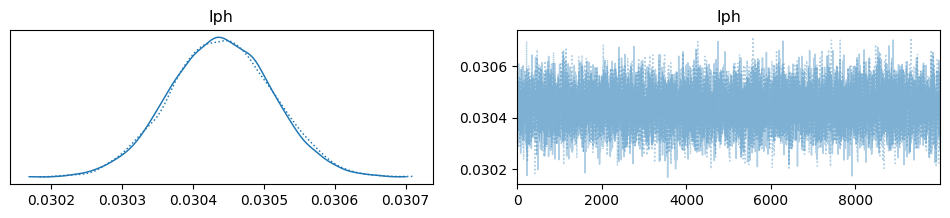

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Iph'))

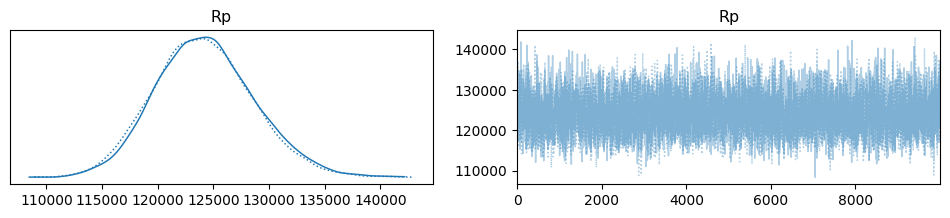

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rp'))

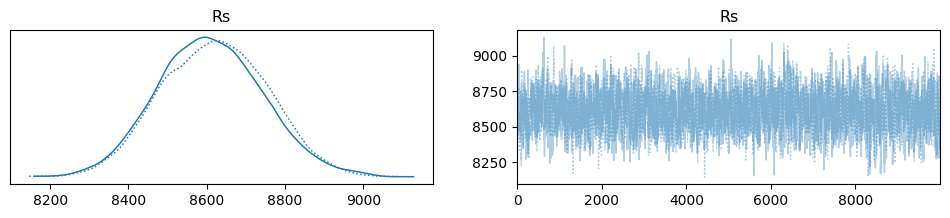

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rs'))

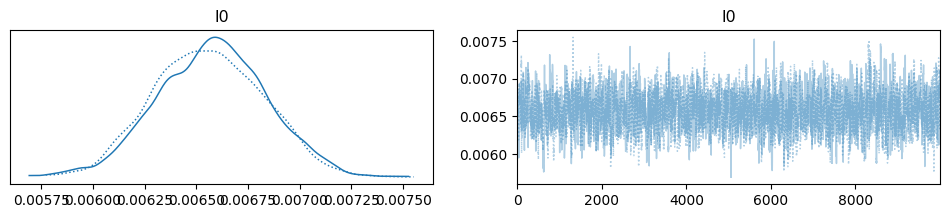

In [ ]:
with model:
  az.plot_trace(trace, var_names=('I0'))

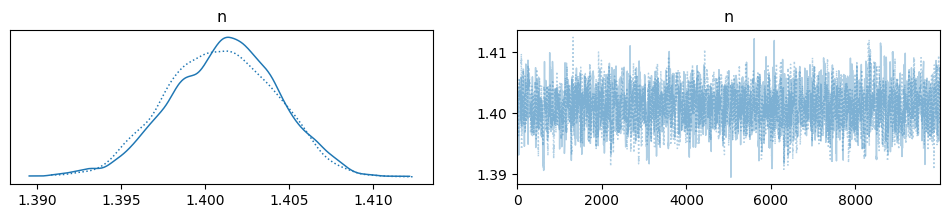

In [ ]:
with model:
  az.plot_trace(trace, var_names=('n'))

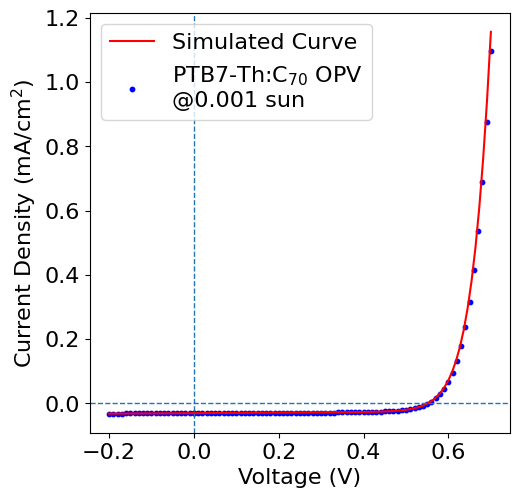

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV\n@0.001 sun'
           )

xmin = np.amin(X)
xmax = np.amax(X)
N = 100
X_range = np.linspace(xmin, xmax, num=N, endpoint=True )

Q = az.summary(trace)
Iph_m = Q.loc['Iph','mean']
Rp_m = Q.loc['Rp','mean']
Rs_m = Q.loc['Rs','mean']
I0_m = Q.loc['I0','mean']
n_m = Q.loc['n','mean']
I_list = calcI(Iph_m, Rp_m, Rs_m, I0_m, n_m, X_range)

ax1.plot(X_range, I_list*1e3, color='red',
            label='Simulated Curve'
           )

#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
handles, labels = ax1.get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1])